# **House Price Prediction**


## **1.	Dataset Selection & Handling**

*   Select any dataset with at least 200 samples and 5 features.
*   Import and summarize the dataset (rows, columns, data types).





In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from google.colab import files
uploaded = files.upload()

Saving Real estate valuation data set.xlsx to Real estate valuation data set.xlsx


In [14]:
df=pd.read_excel('Real estate valuation data set.xlsx')

print("First five rows:\n",df.head())
print("\nNumber of rows and columns:",df.shape)
print("\nColumn names:\n",df.columns.tolist())
print("\nData types:\n",df.dtypes)
print("\nDataset information:")
df.info()

First five rows:
    No  X1 transaction date  X2 house age  \
0   1          2012.916667          32.0   
1   2          2012.916667          19.5   
2   3          2013.583333          13.3   
3   4          2013.500000          13.3   
4   5          2012.833333           5.0   

   X3 distance to the nearest MRT station  X4 number of convenience stores  \
0                                84.87882                               10   
1                               306.59470                                9   
2                               561.98450                                5   
3                               561.98450                                5   
4                               390.56840                                5   

   X5 latitude  X6 longitude  Y house price of unit area  
0     24.98298     121.54024                        37.9  
1     24.98034     121.53951                        42.2  
2     24.98746     121.54391                        47.3  
3     24.987

## **2.	Data Pre-processing**

*   Handle missing values and outliers.
*   Perform necessary transformations (scaling/encoding if required).





In [15]:
print("Missing values:\n",df.isnull().sum())
print("\nDuplicate rows:",df.duplicated().sum())
print("\nSummary statistics:\n",df.describe())

df=df.drop_duplicates()
df=df.drop(columns=['No'])

print("\nShape after removing duplicates and ID:",df.shape)


Missing values:
 No                                        0
X1 transaction date                       0
X2 house age                              0
X3 distance to the nearest MRT station    0
X4 number of convenience stores           0
X5 latitude                               0
X6 longitude                              0
Y house price of unit area                0
dtype: int64

Duplicate rows: 0

Summary statistics:
                No  X1 transaction date  X2 house age  \
count  414.000000           414.000000    414.000000   
mean   207.500000          2013.148953     17.712560   
std    119.655756             0.281995     11.392485   
min      1.000000          2012.666667      0.000000   
25%    104.250000          2012.916667      9.025000   
50%    207.500000          2013.166667     16.100000   
75%    310.750000          2013.416667     28.150000   
max    414.000000          2013.583333     43.800000   

       X3 distance to the nearest MRT station  \
count                  

In [16]:
numeric_cols=df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    q1=df[col].quantile(0.25)
    q3=df[col].quantile(0.75)
    iqr=q3-q1
    lower=q1-1.5*iqr
    upper=q3+1.5*iqr
    count=((df[col]<lower)|(df[col]>upper)).sum()
    print(f"{col}: {count} potential outliers")

X1 transaction date: 0 potential outliers
X2 house age: 0 potential outliers
X3 distance to the nearest MRT station: 37 potential outliers
X4 number of convenience stores: 0 potential outliers
X5 latitude: 8 potential outliers
X6 longitude: 35 potential outliers
Y house price of unit area: 3 potential outliers


In [17]:
X=df.drop(columns=['Y house price of unit area'])
y=df['Y house price of unit area']

print("Features shape:",X.shape)
print("Target shape:",y.shape)
print("\nMissing values in features:\n",X.isnull().sum())

Features shape: (414, 6)
Target shape: (414,)

Missing values in features:
 X1 transaction date                       0
X2 house age                              0
X3 distance to the nearest MRT station    0
X4 number of convenience stores           0
X5 latitude                               0
X6 longitude                              0
dtype: int64


In [18]:
from sklearn.model_selection import train_test_split as tts
from sklearn.preprocessing import StandardScaler as ss

X_train,X_test,y_train,y_test=tts(
    X,y,test_size=0.2,random_state=42
)

scaler=ss()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

print("Training samples:",X_train.shape[0])
print("Testing samples:",X_test.shape[0])

Training samples: 331
Testing samples: 83


## **3.	Exploratory Data Analysis (EDA)**
*   Compute descriptive statistics (mean, variance, skewness, kurtosis, percentiles).
*   Visualize with at least 2 plots (histogram, boxplot, scatter plot, or correlation heatmap).

In [19]:
print("Mean:\n",df.mean())
print("\nVariance:\n",df.var())
print("\nSkewness:\n",df.skew())
print("\nKurtosis:\n",df.kurtosis())
print("\nPercentiles:\n",df.quantile([0.25,0.50,0.75]))

Mean:
 X1 transaction date                       2013.148953
X2 house age                                17.712560
X3 distance to the nearest MRT station    1083.885689
X4 number of convenience stores              4.094203
X5 latitude                                 24.969030
X6 longitude                               121.533361
Y house price of unit area                  37.980193
dtype: float64

Variance:
 X1 transaction date                       7.952136e-02
X2 house age                              1.297887e+02
X3 distance to the nearest MRT station    1.592921e+06
X4 number of convenience stores           8.676334e+00
X5 latitude                               1.540130e-04
X6 longitude                              2.355360e-04
Y house price of unit area                1.851365e+02
dtype: float64

Skewness:
 X1 transaction date                      -0.150834
X2 house age                              0.382926
X3 distance to the nearest MRT station    1.888757
X4 number of convenienc

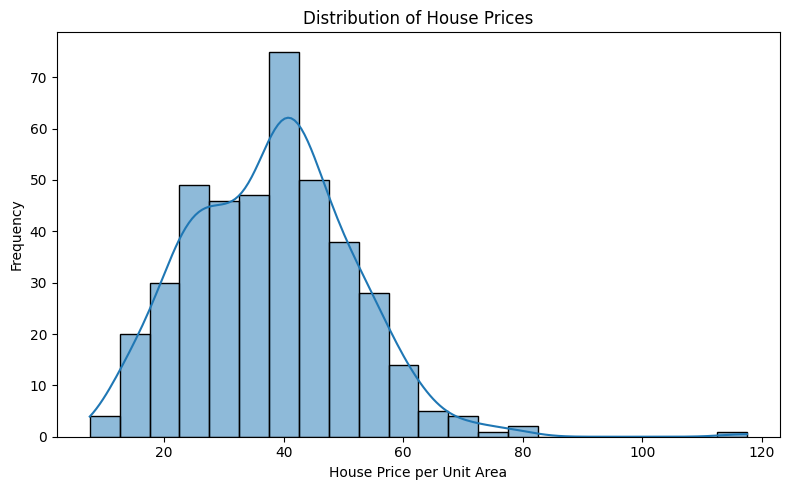

In [20]:
plt.figure(figsize=(8,5))
sns.histplot(y,kde=True)
plt.title("Distribution of House Prices")
plt.xlabel("House Price per Unit Area")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

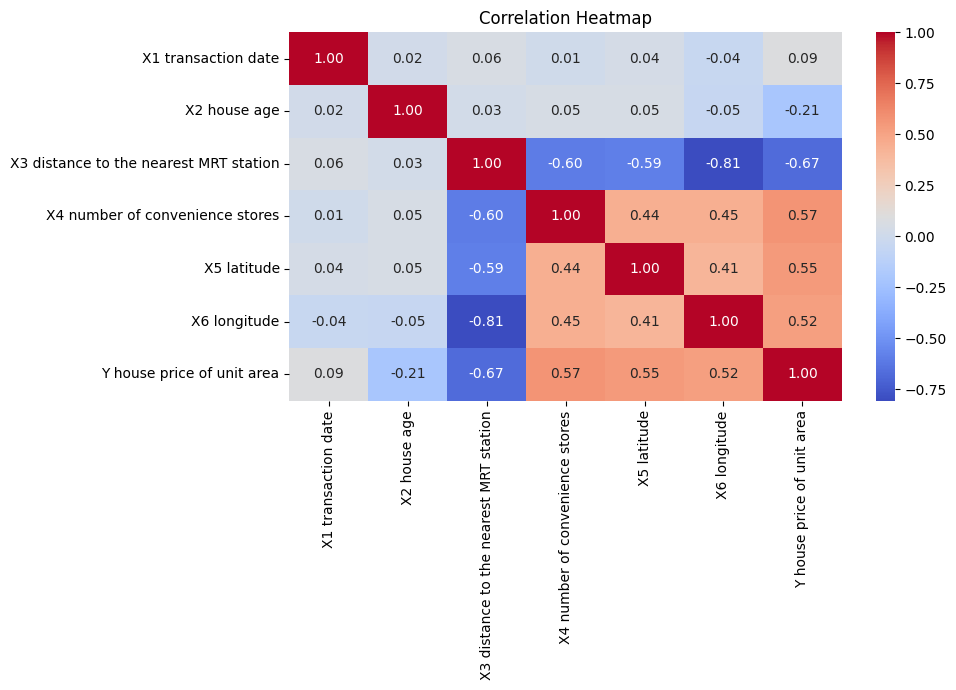

In [21]:
plt.figure(figsize=(10,7))
sns.heatmap(df.corr(),annot=True,cmap='coolwarm',fmt='.2f')
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## **4.	Model Selection & Training**
Choose ONE model from below and train the chosen model on your dataset:


*   Regression: Linear Regression, Polynomial Regression
*   Classification: Logistic Regression, Decision Tree, kNN, SVM
*   Clustering: K-means, Hierarchical
*   Dimensionality Reduction: PCA, ICA

In [22]:
from sklearn.linear_model import LinearRegression

model=LinearRegression()
model.fit(X_train_scaled,y_train)

y_pred=model.predict(X_test_scaled)

print("Model trained successfully.")
print("Intercept:",model.intercept_)
print("Coefficients:",model.coef_)

Model trained successfully.
Intercept: 38.39154078549675
Coefficients: [ 1.53045115 -3.06272616 -5.78697934  3.21900234  2.85518251 -0.44117008]


## **5.	Evaluation**

*   For Regression: Report MSE, RMSE, R².
*   For Classification: Report Accuracy, Precision, Recall, F1-score.
*   For Clustering: Report Silhouette Score and visualize clusters.
*   For Dimensionality Reduction: Show explained variance and 2D visualization.

In [23]:
from sklearn.metrics import mean_squared_error,r2_score

mse=mean_squared_error(y_test,y_pred)
rmse=np.sqrt(mse)
r2=r2_score(y_test,y_pred)

print("Mean Squared Error (MSE):",round(mse,3))
print("Root Mean Squared Error (RMSE):",round(rmse,3))
print("R-squared (R²):",round(r2,3))

Mean Squared Error (MSE): 53.502
Root Mean Squared Error (RMSE): 7.315
R-squared (R²): 0.681
